# Plume profiles

Placeholder notebook (to be extended): crosswind profiles on the five arcs, vertical profiles on the towers, and peak concentration against distance.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))  # notebooks/ (for pgdata)
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import pgdata
arcs, towers = pgdata.arcs(), pgdata.towers()
len(arcs), len(towers)

(30510, 2808)

In [2]:
RUN = "43"  # any run label, e.g. "35S"

## Crosswind profile on each arc

Gaps are printed blanks (no measurable concentration); lines are not drawn across them.

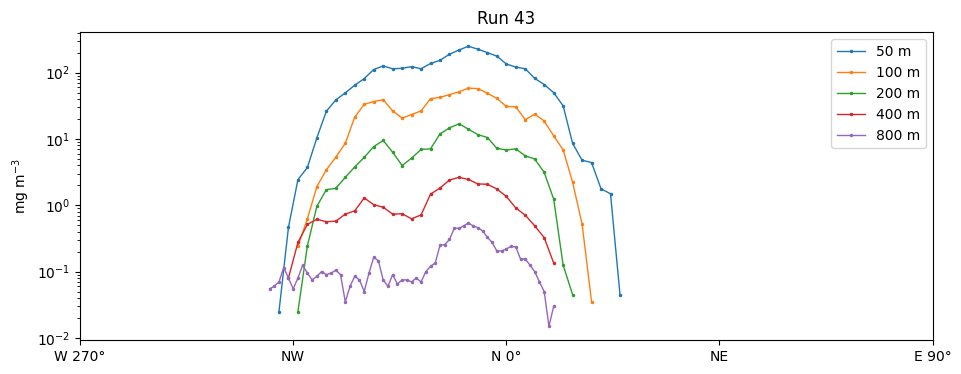

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
for arc in pgdata.ARCS_M:
    d = arcs[(arcs.run == RUN) & (arcs.arc_m == arc)].sort_values("post")
    c = d["concentration_mg_m3"].where(d["status"] == "value")
    ax.plot(d["bearing_unwrapped"], c, marker=".", ms=3, lw=1, label=f"{arc} m")
ax.set_yscale("log"); ax.set_xlim(270, 450)
ax.set_xticks([270, 315, 360, 405, 450], ["W 270°", "NW", "N 0°", "NE", "E 90°"])
ax.set_ylabel("mg m$^{-3}$"); ax.set_title(f"Run {RUN}"); ax.legend(); plt.show()

## Vertical profiles on the towers

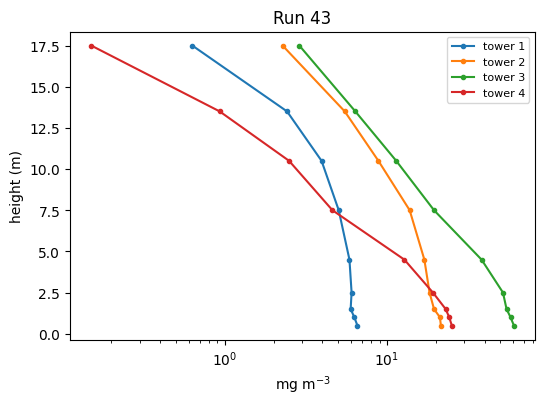

In [4]:
d = towers[(towers.run == RUN) & (towers.status == "value")]
fig, ax = plt.subplots(figsize=(6, 4))
for t, g in d.groupby("tower"):
    g = g.sort_values("height_m"); ax.plot(g["concentration_mg_m3"], g["height_m"], marker="o", ms=3, label=f"tower {t}")
ax.set_xscale("log"); ax.set_xlabel("mg m$^{-3}$"); ax.set_ylabel("height (m)"); ax.legend(fontsize=8)
ax.set_title(f"Run {RUN}" + ("" if len(d) else " (no tower data)")); plt.show()

## Peak concentration against distance, all runs

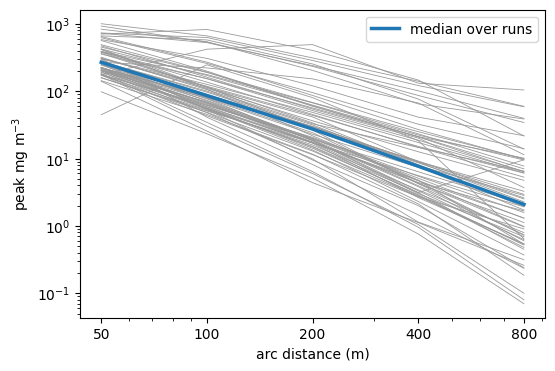

In [5]:
peak = arcs[arcs.status == "value"].groupby(["run", "arc_m"])["concentration_mg_m3"].max().unstack()
fig, ax = plt.subplots(figsize=(6, 4))
for run, row in peak.iterrows():
    ax.plot(row.index, row.values, color="0.6", lw=0.6)
ax.plot(peak.columns, peak.median(), color="C0", lw=2.5, label="median over runs")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(pgdata.ARCS_M, pgdata.ARCS_M)
ax.set_xlabel("arc distance (m)"); ax.set_ylabel("peak mg m$^{-3}$"); ax.legend(); plt.show()